# 04 Correlation and regression: how far do world prices reach Bangladeshi markets?

This notebook covers the BUS173 topics on correlation, simple regression and multiple regression. The question is a practical one for importers, traders and the Ministry of Food: when the world price of rice, wheat or palm oil moves, how much of that move shows up in Bangladeshi retail prices, and how fast?

Data:

- Domestic prices: WFP national monthly retail prices for the four long-basket staples (coarse rice, atta, masur lentils, palm oil), 2006 onwards.
- World prices: World Bank Pink Sheet monthly prices in US dollars. The Pink Sheet file used here ends in December 2025, so every model that uses world prices stops there.
- Exchange rate: IMF BDT per USD, monthly average.
- Weather: the national average rainfall anomaly (percent above or below the 2000-2025 mean for that month, averaged over divisions) and a dummy for months with a known major flood.
- Ramadan: share of the month that falls in Ramadan.

Most variables are monthly changes in logs, multiplied by 100, so they read as percent changes. Every number quoted in the README goes to `outputs/tables/key_facts_regression.csv`. Helper functions are in `src/regression.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from plot_utils import *
import regression as rg
warnings.filterwarnings("ignore", category=FutureWarning)
set_style()
SRC_REG = ("Source: WFP retail prices via HDX; World Bank Pink Sheet (to Dec 2025); IMF exchange rate; "
           "NASA POWER rainfall; author's calculations.")
df = rg.load_monthly()
facts = []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")
fact("sample_first_month", "2006-01", "First month loaded for notebook 04")
fact("sample_last_month", rg.WORLD_END[:7], "Last month with Pink Sheet world prices")
df[[f"d_{s}" for s in rg.STAPLES] + ["d_bdt_per_usd", "rain_anom"]].describe().round(2)

sample_first_month: 2006-01
sample_last_month: 2025-12


,d_rice_coarse,d_atta,d_lentil_masur,d_palm_oil,d_bdt_per_usd,rain_anom
count,232.00,232.00,235.00,217.00,239.00,240.00
mean,0.44,0.41,0.34,0.41,0.26,6.61
std,3.62,3.55,3.41,4.22,0.89,89.52
min,-11.47,-17.97,-12.08,-22.93,-2.63,-100.00
25%,-1.49,-0.99,-1.19,-1.16,-0.00,-49.45
50%,0.20,-0.01,0.01,0.23,0.03,-13.58
75%,2.20,1.18,2.05,1.98,0.29,36.80
max,15.34,14.59,18.91,14.16,5.42,469.07


## 1. Correlation

We correlate monthly percent changes, not price levels (section 2 shows why). Pearson's r measures linear association; Spearman's rho uses ranks and is less sensitive to a few very large months, which food prices have. The 95% confidence intervals use Fisher's z transformation: z = atanh(r) is roughly normal with standard error 1/sqrt(n - 3).

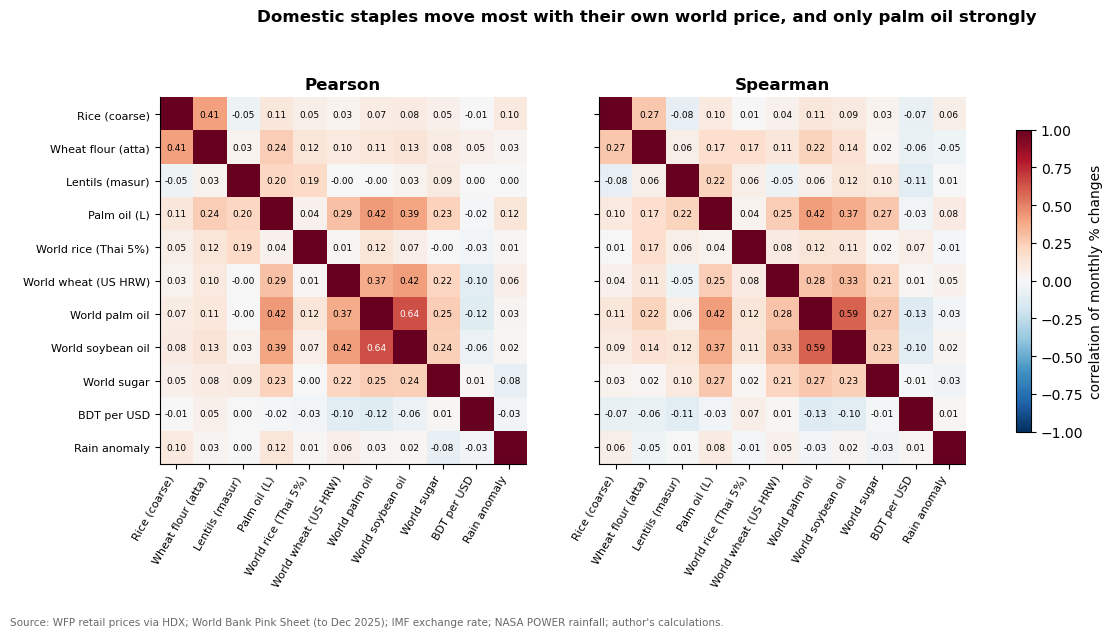

corr_rice_pearson: 0.055
corr_rice_ci: -0.07 to 0.18
corr_rice_spearman: 0.007
corr_wheat_pearson: 0.099
corr_wheat_ci: -0.03 to 0.23
corr_wheat_spearman: 0.113
corr_palm_pearson: 0.425
corr_palm_ci: 0.31 to 0.53
corr_palm_spearman: 0.418


,var1,var2,n,pearson,pearson_p,pearson_ci_low,pearson_ci_high,spearman,spearman_p,spearman_ci_low,spearman_ci_high
3,Rice (coarse),World rice (Thai 5%),232,0.055,0.407,-0.075,0.182,0.007,0.915,-0.122,0.136
13,Wheat flour (atta),World wheat (US HRW),232,0.099,0.132,-0.030,0.225,0.113,0.087,-0.016,0.238
29,Palm oil (L),World palm oil,217,0.425,0.000,0.309,0.528,0.418,0.000,0.302,0.522


In [2]:
cols = [f"d_{s}" for s in rg.STAPLES] + [f"d_{w}" for w in rg.WORLD] + ["d_bdt_per_usd", "rain_anom"]
labels = {f"d_{s}": ITEM_LABEL[s] for s in rg.STAPLES}
labels.update({f"d_{w}": rg.WORLD_LABEL[w] for w in rg.WORLD})
labels.update({"d_bdt_per_usd": "BDT per USD", "rain_anom": "Rain anomaly"})
ct = rg.corr_table(df, cols, labels)
ct.round(4).to_csv(TAB / "regression_correlations.csv", index=False)
pear = df[cols].corr(method="pearson").rename(index=labels, columns=labels)
spear = df[cols].corr(method="spearman").rename(index=labels, columns=labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, m, t in [(axes[0], pear, "Pearson"), (axes[1], spear, "Spearman")]:
    im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index if t == "Pearson" else [], fontsize=8)
    ax.grid(False); ax.set_title(t)
    for (i, j), v in np.ndenumerate(m.values):
        if i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=axes, shrink=0.7, label="correlation of monthly % changes")
fig.suptitle("Domestic staples move most with their own world price, and only palm oil strongly", fontweight="bold")
fig.text(0.01, -0.12, SRC_REG, fontsize=7.5, color="dimgray")  # below the rotated tick labels
fig.savefig(FIG / "fig20_correlation_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

own = ct[((ct.var1 == ITEM_LABEL["palm_oil"]) & (ct.var2 == "World palm oil")) |
         ((ct.var1 == ITEM_LABEL["atta"]) & (ct.var2 == "World wheat (US HRW)")) |
         ((ct.var1 == ITEM_LABEL["rice_coarse"]) & (ct.var2 == "World rice (Thai 5%)"))]
for _, r in own.iterrows():
    key = r.var2.split()[1].lower().replace("(", "")
    fact(f"corr_{key}_pearson", round(r.pearson, 3), f"Pearson r, monthly % change, {r.var1} vs {r.var2}, n={r.n}")
    fact(f"corr_{key}_ci", f"{r.pearson_ci_low:.2f} to {r.pearson_ci_high:.2f}", "Fisher-z 95% CI of that r")
    fact(f"corr_{key}_spearman", round(r.spearman, 3), "Spearman rho, same pair")
own.round(3)

Same-month correlations understate the link, because import prices take one to three months to reach shops (imports are shipped, cleared and milled first). The regressions below allow for that with lags. Rice is mostly grown at home, so we expect its link to the Thai export price to be the weakest of the three.

## 2. A spurious correlation: levels versus changes

Two series that both trend upward will show a high correlation in levels even if nothing connects them. Food prices in taka have risen for twenty years, and so has almost every other price in taka. The table below compares the correlation of log levels with the correlation of monthly changes for some pairs. The simulation then draws two random walks that are independent by construction and records the correlation of their levels.

,domestic,other,r_levels,r_changes,n_changes
0,Rice (coarse),World wheat (US HRW),0.323,0.033,232
1,Lentils (masur),World sugar,0.504,0.089,235
2,Palm oil (L),World palm oil,0.683,0.425,217
3,Rice (coarse),BDT per USD,0.777,-0.007,232


spurious_rw_share_significant: 0.848
spurious_diff_share_significant: 0.039
spurious_rice_vs_wheat_levels_r: 0.323
spurious_rice_vs_wheat_changes_r: 0.033


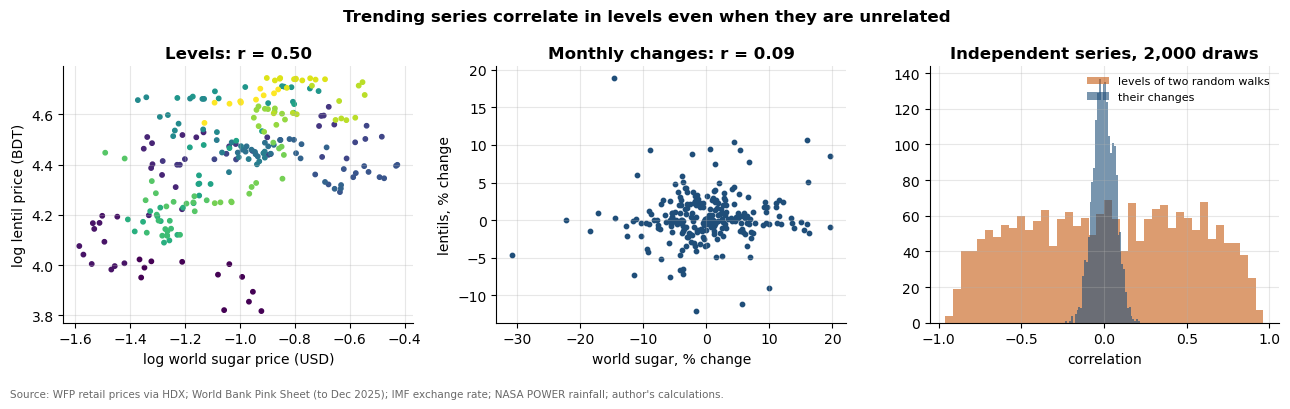

In [3]:
pairs = [("rice_coarse", "world_wheat_us_hrw"), ("lentil_masur", "world_sugar_world"),
         ("palm_oil", "world_palm_oil"), ("rice_coarse", "bdt_per_usd")]
rows = []
for a, b in pairs:
    lv = df[[f"l_{a}", f"l_{b}"]].dropna(); ch = df[[f"d_{a}", f"d_{b}"]].dropna()
    rows.append({"domestic": ITEM_LABEL[a], "other": rg.WORLD_LABEL[b],
                 "r_levels": lv.corr().iloc[0, 1], "r_changes": ch.corr().iloc[0, 1], "n_changes": len(ch)})
spur = pd.DataFrame(rows); spur.round(3).to_csv(TAB / "regression_spurious_demo.csv", index=False)
display(spur.round(3))

rng = np.random.default_rng(173)
T, R = 240, 2000
lev = np.array([np.corrcoef(rng.normal(size=T).cumsum(), rng.normal(size=T).cumsum())[0, 1] for _ in range(R)])
dif = np.array([np.corrcoef(rng.normal(size=T), rng.normal(size=T))[0, 1] for _ in range(R)])
share_lev = (np.abs(lev) > 2 / np.sqrt(T)).mean(); share_dif = (np.abs(dif) > 2 / np.sqrt(T)).mean()
fact("spurious_rw_share_significant", round(share_lev, 3), f"Share of {R} pairs of independent 240-month random walks with |r| > 2/sqrt(T) in levels")
fact("spurious_diff_share_significant", round(share_dif, 3), "Same share for their changes (should be about 0.05)")
r0 = spur.iloc[0]
fact("spurious_rice_vs_wheat_levels_r", round(r0.r_levels, 3), "Correlation of log levels, domestic rice vs world wheat (USD)")
fact("spurious_rice_vs_wheat_changes_r", round(r0.r_changes, 3), "Correlation of monthly changes, same pair")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]; d = df[["l_lentil_masur", "l_world_sugar_world"]].dropna()
ax.scatter(d.l_world_sugar_world, d.l_lentil_masur, s=10, c=d.index.year, cmap="viridis")
ax.set_xlabel("log world sugar price (USD)"); ax.set_ylabel("log lentil price (BDT)")
ax.set_title(f"Levels: r = {d.corr().iloc[0, 1]:.2f}")
ax = axes[1]; d = df[["d_lentil_masur", "d_world_sugar_world"]].dropna()
ax.scatter(d.d_world_sugar_world, d.d_lentil_masur, s=10, color=BLUE)
ax.set_xlabel("world sugar, % change"); ax.set_ylabel("lentils, % change")
ax.set_title(f"Monthly changes: r = {d.corr().iloc[0, 1]:.2f}")
ax = axes[2]
ax.hist(lev, bins=40, alpha=0.6, color=ORANGE, label="levels of two random walks")
ax.hist(dif, bins=40, alpha=0.6, color=BLUE, label="their changes")
ax.set_xlabel("correlation"); ax.set_title("Independent series, 2,000 draws"); ax.legend(fontsize=8)
fig.suptitle("Trending series correlate in levels even when they are unrelated", fontweight="bold")
save(fig, "fig21_spurious_correlation", SRC_REG); plt.show()

Lentil prices in Bangladesh and the world sugar price have nothing to do with each other, yet their levels look related because both drift up over time. In changes the link disappears. In the simulation, the two independent random walks pass a naive 5% significance test far more often than 5% of the time. The fix is to work with changes (or to test for cointegration, which notebook 05 does). Everything below uses changes for inference.

## 3. Simple regression: domestic rice on the world rice price in taka

Model in levels: log(domestic rice) = a + b log(Thai rice price x BDT per USD) + e. The slope b is an elasticity: a 1% higher world price in taka goes with a b% higher domestic price. The levels regression has the problem from section 2, so we also run it in monthly changes. We do the same for atta on wheat and palm oil on world palm oil for comparison.

In [4]:
rows, simple = [], {}
for item in ["rice_coarse", "atta", "palm_oil"]:
    w = rg.WORLD_FOR[item]
    for form, yv, xv in [("levels", f"l_{item}", f"l_{w}_bdt"), ("changes", f"d_{item}", f"d_{w}_bdt")]:
        d = df[[yv, xv]].dropna()
        X = sm.add_constant(d[xv].rename("world_bdt"))
        res = sm.OLS(d[yv], X).fit(cov_type="HAC", cov_kwds={"maxlags": rg.hac_lags(len(d))})
        simple[(item, form)] = (res, d, xv, yv)
        ci = res.conf_int().loc["world_bdt"]
        rows.append({"item": item, "form": form, "slope": res.params.world_bdt, "se_hac": res.bse.world_bdt,
                     "ci_low": ci[0], "ci_high": ci[1], "r2": res.rsquared,
                     "durbin_watson": sm.stats.durbin_watson(res.resid), "n": int(res.nobs)})
st = pd.DataFrame(rows); st.round(4).to_csv(TAB / "regression_simple.csv", index=False)
for (item, form), (res, *_ ) in simple.items():
    if item == "rice_coarse":
        ci = res.conf_int().loc["world_bdt"]
        fact(f"simple_rice_{form}_slope", round(res.params.world_bdt, 3), f"OLS slope, {form}, log domestic rice on log Thai rice in BDT")
        fact(f"simple_rice_{form}_ci", f"{ci[0]:.2f} to {ci[1]:.2f}", "95% CI, Newey-West SE")
        fact(f"simple_rice_{form}_r2", round(res.rsquared, 3), "R squared")
        fact(f"simple_rice_{form}_dw", round(sm.stats.durbin_watson(res.resid), 2), "Durbin-Watson of residuals")
st.round(3)

simple_rice_levels_slope: 0.71
simple_rice_levels_ci: 0.52 to 0.90
simple_rice_levels_r2: 0.452
simple_rice_levels_dw: 0.06
simple_rice_changes_slope: 0.033
simple_rice_changes_ci: -0.05 to 0.12
simple_rice_changes_r2: 0.003
simple_rice_changes_dw: 1.37


,item,form,slope,se_hac,ci_low,ci_high,r2,durbin_watson,n
0,rice_coarse,levels,0.710,0.096,0.522,0.898,0.452,0.061,236
1,rice_coarse,changes,0.033,0.043,-0.052,0.117,0.003,1.375,232
2,atta,levels,0.631,0.072,0.490,0.771,0.681,0.125,235
3,atta,changes,0.055,0.029,-0.002,0.113,0.011,1.102,232
4,palm_oil,levels,0.908,0.040,0.829,0.987,0.884,0.328,222
5,palm_oil,changes,0.263,0.054,0.158,0.369,0.183,1.507,217


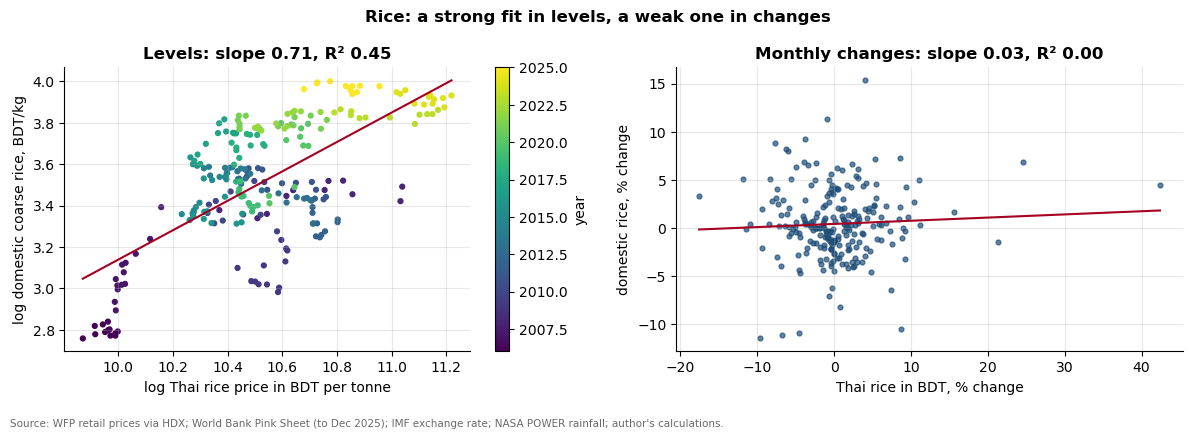

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
res, d, xv, yv = simple[("rice_coarse", "levels")]
ax = axes[0]; sc = ax.scatter(d[xv], d[yv], s=12, c=d.index.year, cmap="viridis")
xs = np.linspace(d[xv].min(), d[xv].max(), 50)
ax.plot(xs, res.params.const + res.params.world_bdt * xs, color=RED)
ax.set_xlabel("log Thai rice price in BDT per tonne"); ax.set_ylabel("log domestic coarse rice, BDT/kg")
ax.set_title(f"Levels: slope {res.params.world_bdt:.2f}, R² {res.rsquared:.2f}"); fig.colorbar(sc, ax=ax, label="year")
res, d, xv, yv = simple[("rice_coarse", "changes")]
ax = axes[1]; ax.scatter(d[xv], d[yv], s=12, color=BLUE, alpha=0.7)
xs = np.linspace(d[xv].min(), d[xv].max(), 50)
ax.plot(xs, res.params.const + res.params.world_bdt * xs, color=RED)
ax.set_xlabel("Thai rice in BDT, % change"); ax.set_ylabel("domestic rice, % change")
ax.set_title(f"Monthly changes: slope {res.params.world_bdt:.2f}, R² {res.rsquared:.2f}")
fig.suptitle("Rice: a strong fit in levels, a weak one in changes", fontweight="bold")
save(fig, "fig22_simple_regression_rice", SRC_REG); plt.show()

### Residual diagnostics for the simple regression

A regression is only as good as its residuals. For the levels model we look at residuals over time (long runs on one side of zero mean the errors are autocorrelated) and for the changes model at a Q-Q plot against the normal distribution.

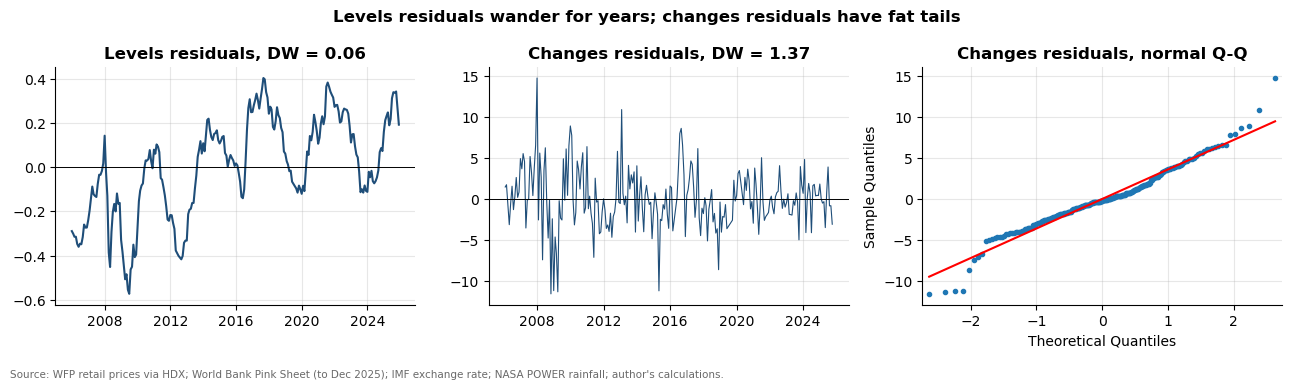

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
rl = simple[("rice_coarse", "levels")][0].resid; rc = simple[("rice_coarse", "changes")][0].resid
axes[0].plot(rl.index, rl, color=BLUE); axes[0].axhline(0, color="k", lw=0.7)
axes[0].set_title(f"Levels residuals, DW = {sm.stats.durbin_watson(rl):.2f}")
axes[1].plot(rc.index, rc, color=BLUE, lw=0.8); axes[1].axhline(0, color="k", lw=0.7)
axes[1].set_title(f"Changes residuals, DW = {sm.stats.durbin_watson(rc):.2f}")
sm.qqplot(rc, line="s", ax=axes[2], markersize=3); axes[2].set_title("Changes residuals, normal Q-Q")
fig.suptitle("Levels residuals wander for years; changes residuals have fat tails", fontweight="bold")
save(fig, "fig23_simple_regression_residuals", SRC_REG); plt.show()

The Durbin-Watson statistic for the levels regression is far below 2, the usual sign of a spurious regression in levels. In changes the residuals are much closer to independent, but the Q-Q plot shows fat tails: a few months (the 2007-08 food crisis, the 2020 and 2022 shocks) move far more than a normal distribution allows. That is why we use Newey-West standard errors, which are robust to both problems in large samples, and why the multiple regression adds lags.

## 4. Multiple regression: the pass-through model

For each staple i, month t:

d log P_i,t = a + sum over k = 0..3 of b_k d log W_i,t-k + c1 rain anomaly_t + c2 flood_t + c3 Ramadan share_t + c4 design break_t + month dummies + e_t

- W is the matching world price converted to taka (Thai rice, US hard red winter wheat, palm oil). Lentils have no Pink Sheet series, so for lentils we use the exchange rate itself (lags 0 to 3).
- The long-run pass-through is the sum b_0 + b_1 + b_2 + b_3: the percent change in the domestic price three months after a 1% permanent change in the world price.
- "Design break" is a dummy for July 2020, the month WFP switched from division series to district markets, so that the switch is not read as a price change.
- Standard errors are Newey-West (HAC) with the rule-of-thumb lag length floor(4 (n/100)^(2/9)).

A second version splits the taka world price into the dollar world price and the exchange rate, each with lags 0 to 3. That shows whether a move in the taka passes through as strongly as a move in the dollar price.

In [7]:
models, coefs, lr_rows, diag_rows, ftests, vifs = {}, [], [], [], [], []
for item in rg.STAPLES:
    for spec in ["bdt", "usd"]:
        if item == "lentil_masur" and spec == "usd":
            continue
        y, X = rg.design(df, item, world=spec)
        ols, hac = rg.fit(y, X)
        name = f"main_{spec}" if item != "lentil_masur" else "main_fx_only"
        models[(item, spec)] = (ols, hac, y, X)
        coefs.append(rg.coef_table(hac, name, item))
        groups = {"world": [c for c in X if c.startswith("world_")], "fx": [c for c in X if c.startswith("fx_")]}
        for g, names in groups.items():
            if names:
                lr = rg.sum_test(hac, names); lr1 = rg.sum_test(hac, names, 1.0)
                lr_rows.append({"item": item, "model": name, "driver": g, **lr,
                                "wald_full_passthrough_stat": lr1["wald_stat"], "wald_full_passthrough_p": lr1["wald_p"],
                                "n": int(hac.nobs)})
                f, p, k = rg.joint_f(hac, names)
                ftests.append({"item": item, "model": name, "test": f"all {g} lags = 0", "F": f, "p": p, "df_num": k})
        mnames = [c for c in X if c.startswith("m_")]
        f, p, k = rg.joint_f(hac, mnames)
        ftests.append({"item": item, "model": name, "test": "month dummies = 0", "F": f, "p": p, "df_num": k})
        f, p, k = rg.joint_f(hac, ["rain_anom", "flood"])
        ftests.append({"item": item, "model": name, "test": "rain anomaly and flood = 0", "F": f, "p": p, "df_num": k})
        f, p, k = rg.joint_f(hac, [c for c in X if c != "const"])
        ftests.append({"item": item, "model": name, "test": "all slopes = 0 (overall F)", "F": f, "p": p, "df_num": k})
        dg, vif = rg.diagnostics(ols, X)
        diag_rows.append({"item": item, "model": name, **dg})
        vifs += [{"item": item, "model": name, "term": t, "vif": v} for t, v in vif.items()]
coef_df = pd.concat(coefs); lr_df = pd.DataFrame(lr_rows); diag_df = pd.DataFrame(diag_rows)
ft_df = pd.DataFrame(ftests); vif_df = pd.DataFrame(vifs)
coef_df.round(5).to_csv(TAB / "regression_main_coefficients.csv", index=False)
lr_df.round(4).to_csv(TAB / "regression_longrun_passthrough.csv", index=False)
diag_df.round(4).to_csv(TAB / "regression_diagnostics.csv", index=False)
ft_df.round(4).to_csv(TAB / "regression_ftests.csv", index=False)
vif_df.round(3).to_csv(TAB / "regression_vif.csv", index=False)
lr_df[["item", "model", "driver", "sum", "se", "ci_low", "ci_high", "wald_p", "wald_full_passthrough_p", "n"]].round(3)

,item,model,driver,sum,se,ci_low,ci_high,wald_p,wald_full_passthrough_p,n
0,rice_coarse,main_bdt,world,0.156,0.071,0.016,0.295,0.029,0.000,229
1,rice_coarse,main_usd,world,0.183,0.069,0.048,0.318,0.008,0.000,229
2,rice_coarse,main_usd,fx,-0.673,0.362,-1.382,0.035,0.063,0.000,229
3,atta,main_bdt,world,0.364,0.087,0.192,0.535,0.000,0.000,231
4,atta,main_usd,world,0.364,0.087,0.193,0.535,0.000,0.000,231
5,atta,main_usd,fx,0.616,0.723,-0.800,2.032,0.394,0.595,231
6,lentil_masur,main_fx_only,fx,-0.280,0.321,-0.909,0.349,0.383,0.000,232
7,palm_oil,main_bdt,world,0.664,0.070,0.526,0.802,0.000,0.000,217
8,palm_oil,main_usd,world,0.668,0.071,0.528,0.808,0.000,0.000,217
9,palm_oil,main_usd,fx,0.806,0.240,0.335,1.277,0.001,0.420,217


In [8]:
ols, hac, y, X = models[("palm_oil", "bdt")]
print(hac.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                     dy   R-squared:                       0.505
Model:                            OLS   Adj. R-squared:                  0.457
No. Observations:                 217   F-statistic:                     17.10
Covariance Type:                  HAC   Prob (F-statistic):           4.37e-32
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5050      1.238     -0.408      0.683      -2.932       1.922
world_L0       0.1949      0.040      4.904      0.000       0.117       0.273
world_L1       0.2119      0.051      4.123      0.000       0.111       0.313
world_L2       0.1048      0.037      2.845      0.004       0.033       0.177
world_L3       0.1522      0.053      2.882      0.004       0.049       0.256
rain_anom      0.0041      0.002      1.860      0.0

In [9]:
main = lr_df[(lr_df.model.isin(["main_bdt", "main_fx_only"]))]
for _, r in main.iterrows():
    k = r["item"]
    fact(f"lr_passthrough_{k}", round(r["sum"], 3), f"Sum of lag 0-3 coefficients on {'taka world price' if r.driver == 'world' else 'BDT per USD'}, {k}, HAC")
    fact(f"lr_passthrough_{k}_ci", f"{r.ci_low:.2f} to {r.ci_high:.2f}", "95% CI of that sum (Newey-West)")
    fact(f"lr_passthrough_{k}_p_zero", round(r.wald_p, 4), "Wald test p-value, H0: sum = 0")
    fact(f"lr_passthrough_{k}_p_full", round(r.wald_full_passthrough_p, 4), "Wald test p-value, H0: sum = 1 (full pass-through)")
for _, r in diag_df[diag_df.model.isin(["main_bdt", "main_fx_only"])].iterrows():
    fact(f"adj_r2_{r['item']}", round(r.adj_r2, 3), "Adjusted R squared, main model")
po = main[main["item"] == "palm_oil"].iloc[0]
print(f"\nA 10% rise in the world palm oil price in taka raises Bangladeshi retail palm oil prices (national average) by about "
      f"{10 * po['sum']:.1f}% within three months (95% CI {10 * po.ci_low:.1f}% to {10 * po.ci_high:.1f}%).")
fact("palm_oil_10pct_shock_effect_pct", round(10 * po["sum"], 1), "10 x long-run pass-through, palm oil")
fx = lr_df[(lr_df.model == "main_usd") & (lr_df.driver == "fx")]
for _, r in fx.iterrows():
    fact(f"fx_passthrough_{r['item']}", round(r['sum'], 3), "Sum of lag 0-3 coefficients on BDT per USD, dollar world price entered separately")
    fact(f"fx_passthrough_{r['item']}_ci", f"{r.ci_low:.2f} to {r.ci_high:.2f}", "95% CI (Newey-West)")

lr_passthrough_rice_coarse: 0.156
lr_passthrough_rice_coarse_ci: 0.02 to 0.30
lr_passthrough_rice_coarse_p_zero: 0.0286
lr_passthrough_rice_coarse_p_full: 0.0
lr_passthrough_atta: 0.364
lr_passthrough_atta_ci: 0.19 to 0.54
lr_passthrough_atta_p_zero: 0.0
lr_passthrough_atta_p_full: 0.0
lr_passthrough_lentil_masur: -0.28
lr_passthrough_lentil_masur_ci: -0.91 to 0.35
lr_passthrough_lentil_masur_p_zero: 0.3832
lr_passthrough_lentil_masur_p_full: 0.0001
lr_passthrough_palm_oil: 0.664
lr_passthrough_palm_oil_ci: 0.53 to 0.80
lr_passthrough_palm_oil_p_zero: 0.0
lr_passthrough_palm_oil_p_full: 0.0
adj_r2_rice_coarse: 0.059
adj_r2_atta: 0.218
adj_r2_lentil_masur: -0.022
adj_r2_palm_oil: 0.457

A 10% rise in the world palm oil price in taka raises Bangladeshi retail palm oil prices (national average) by about 6.6% within three months (95% CI 5.3% to 8.0%).
palm_oil_10pct_shock_effect_pct: 6.6
fx_passthrough_rice_coarse: -0.673
fx_passthrough_rice_coarse_ci: -1.38 to 0.04
fx_passthrough_atta: 0.

### Dynamic pass-through

The chart below adds the lag coefficients one at a time: the bar at lag 2 is the effect, by the end of month t+2, of a 1% world price rise in month t. The whiskers are 95% intervals for each cumulative sum.

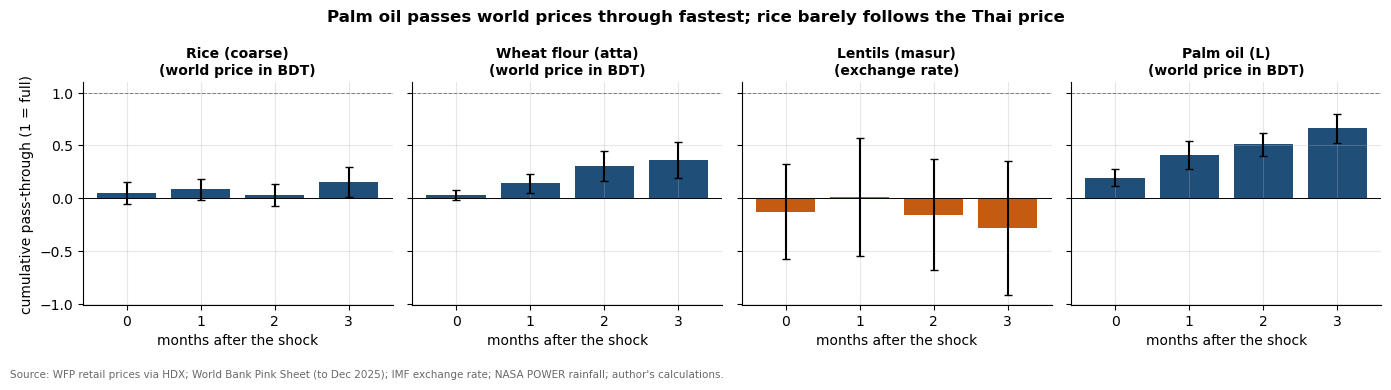

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, item in zip(axes, rg.STAPLES):
    ols, hac, y, X = models[(item, "bdt")]
    var = "world" if item != "lentil_masur" else "fx"
    cum = [rg.sum_test(hac, [f"{var}_L{j}" for j in range(k + 1)]) for k in range(rg.NLAGS + 1)]
    est = np.array([c["sum"] for c in cum]); lo = np.array([c["ci_low"] for c in cum]); hi = np.array([c["ci_high"] for c in cum])
    ax.bar(range(4), est, color=BLUE if var == "world" else ORANGE)
    ax.errorbar(range(4), est, yerr=[est - lo, hi - est], fmt="none", color="k", capsize=3)
    ax.axhline(0, color="k", lw=0.7); ax.axhline(1, color=GREY, lw=0.7, ls="--")
    ax.set_xticks(range(4)); ax.set_xlabel("months after the shock")
    ax.set_title(f"{ITEM_LABEL[item]}\n({'world price in BDT' if var == 'world' else 'exchange rate'})", fontsize=10)
axes[0].set_ylabel("cumulative pass-through (1 = full)")
fig.suptitle("Palm oil passes world prices through fastest; rice barely follows the Thai price", fontweight="bold")
save(fig, "fig24_dynamic_passthrough", SRC_REG); plt.show()

### Diagnostics

- **VIF** checks multicollinearity among the non-dummy regressors. Values above 10 are a warning; lags of a monthly change are only mildly correlated with each other, so we expect low values.
- **Breusch-Pagan** tests whether the residual variance depends on the regressors (heteroskedasticity).
- **Breusch-Godfrey** (12 lags) tests for residual autocorrelation. Durbin-Watson is shown too, but it is not valid with lagged regressors of this kind and BG is the better test.
- **Jarque-Bera** tests normality of the residuals through skewness and kurtosis.

Newey-West standard errors stay valid under heteroskedasticity and autocorrelation, so failing BP or BG does not invalidate the confidence intervals above. Failing JB matters less with 200+ months, since the t-tests rely on the central limit theorem rather than normal errors.

,item,model,n,adj_r2,max_vif,max_vif_term,breusch_pagan_p,breusch_godfrey_p,durbin_watson,jarque_bera_p,kurtosis
0,rice_coarse,main_bdt,229,0.059,1.609,world_L2,0.683,0.000,1.405,0.0,4.462
1,rice_coarse,main_usd,229,0.068,1.593,world_L2,0.485,0.000,1.438,0.0,4.402
2,atta,main_bdt,231,0.218,1.371,flood,0.353,0.000,1.257,0.0,7.823
3,atta,main_usd,231,0.206,1.419,flood,0.506,0.000,1.257,0.0,7.703
4,lentil_masur,main_fx_only,232,-0.022,1.370,fx_L1,0.683,0.001,1.569,0.0,8.124
5,palm_oil,main_bdt,217,0.457,1.413,world_L1,0.010,0.000,1.980,0.0,17.615
6,palm_oil,main_usd,217,0.453,1.902,fx_L1,0.030,0.000,1.974,0.0,17.720


max_vif_all_main_models: 1.61
bg_reject_count: 4
bp_reject_count: 1
jb_reject_count: 4


,item,model,test,F,p,df_num
0,rice_coarse,main_bdt,all world lags = 0,3.2084,0.0139,4
1,rice_coarse,main_bdt,month dummies = 0,3.1050,0.0007,11
2,rice_coarse,main_bdt,rain anomaly and flood = 0,1.5877,0.2068,2
3,rice_coarse,main_bdt,all slopes = 0 (overall F),8.0651,0.0000,19
9,atta,main_bdt,all world lags = 0,4.6906,0.0012,4
10,atta,main_bdt,month dummies = 0,2.1600,0.0177,11
11,atta,main_bdt,rain anomaly and flood = 0,0.9916,0.3727,2
12,atta,main_bdt,all slopes = 0 (overall F),4.3019,0.0000,19
18,lentil_masur,main_fx_only,all fx lags = 0,0.4504,0.7721,4
19,lentil_masur,main_fx_only,month dummies = 0,1.3212,0.2141,11


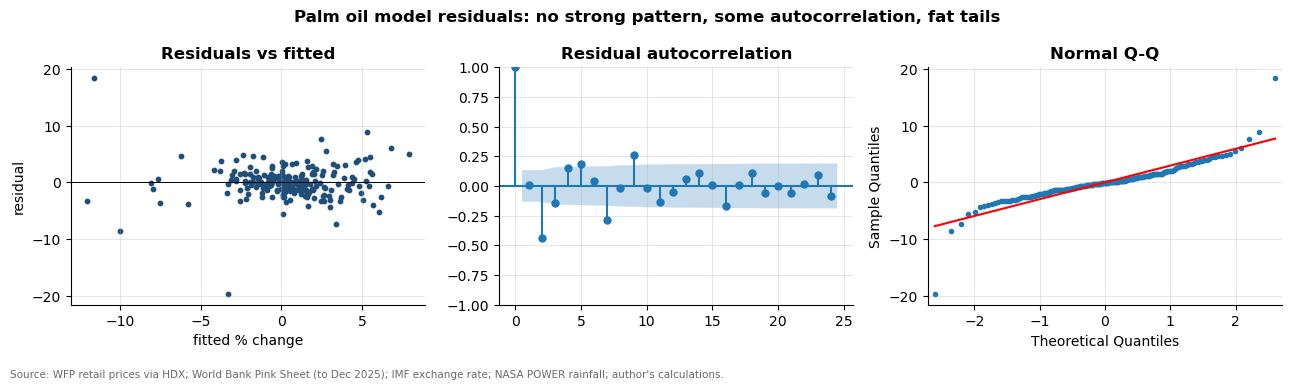

In [11]:
display(diag_df[["item", "model", "n", "adj_r2", "max_vif", "max_vif_term", "breusch_pagan_p", "breusch_godfrey_p",
                 "durbin_watson", "jarque_bera_p", "kurtosis"]].round(3))
d = diag_df[diag_df.model.isin(["main_bdt", "main_fx_only"])]
fact("max_vif_all_main_models", round(d.max_vif.max(), 2), "Largest VIF over the non-dummy regressors of the four main models")
fact("bg_reject_count", int((d.breusch_godfrey_p < 0.05).sum()), "Main models (of 4) where Breusch-Godfrey(12) rejects no autocorrelation at 5%")
fact("bp_reject_count", int((d.breusch_pagan_p < 0.05).sum()), "Main models (of 4) where Breusch-Pagan rejects homoskedasticity at 5%")
fact("jb_reject_count", int((d.jarque_bera_p < 0.05).sum()), "Main models (of 4) where Jarque-Bera rejects normal residuals at 5%")
display(ft_df[ft_df.model.isin(["main_bdt", "main_fx_only"])].round(4))

ols, hac, y, X = models[("palm_oil", "bdt")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(ols.fittedvalues, ols.resid, s=10, color=BLUE); axes[0].axhline(0, color="k", lw=0.7)
axes[0].set_xlabel("fitted % change"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals vs fitted")
sm.graphics.tsa.plot_acf(ols.resid, lags=24, ax=axes[1], title="Residual autocorrelation")
sm.qqplot(ols.resid, line="s", ax=axes[2], markersize=3); axes[2].set_title("Normal Q-Q")
fig.suptitle("Palm oil model residuals: no strong pattern, some autocorrelation, fat tails", fontweight="bold")
save(fig, "fig25_main_model_residuals", SRC_REG); plt.show()

### Out-of-sample check

A model that fits well inside the sample can still forecast badly. We refit each main model on data up to December 2019 and use it to predict monthly price changes from January 2020 to December 2025, given the actual world prices, exchange rate and weather. The benchmark is the training-sample mean change (a forecaster who ignores world prices). Lower root mean squared error (RMSE) is better. The test period includes the 2020 WFP design change, COVID and the 2022 depreciation, so it is a hard test.

oos_rmse_ratio_rice_coarse: 1.111
oos_rmse_ratio_atta: 1.025
oos_rmse_ratio_lentil_masur: 1.158
oos_rmse_ratio_palm_oil: 0.692


,item,n_train,n_test,rmse_model,rmse_mean_benchmark,rmse_ratio,oos_r2,corr_pred_actual
0,rice_coarse,161,68,2.460,2.213,1.111,-0.235,0.221
1,atta,161,70,2.945,2.872,1.025,-0.051,0.268
2,lentil_masur,162,70,4.128,3.565,1.158,-0.340,-0.223
3,palm_oil,147,70,2.939,4.249,0.692,0.521,0.705


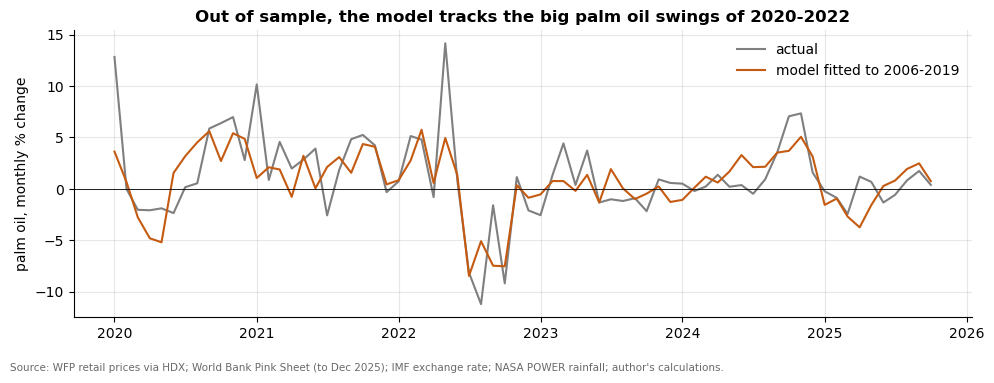

In [12]:
oos = []
for item in rg.STAPLES:
    ols, hac, y, X = models[(item, "bdt")]
    tr, te = y.index < "2020-01-01", y.index >= "2020-01-01"
    Xtr = X[tr].loc[:, X[tr].std().gt(0) | (X.columns == "const")]
    m = sm.OLS(y[tr], Xtr).fit()
    pred = m.predict(X.loc[te, Xtr.columns])
    rmse = np.sqrt(((y[te] - pred) ** 2).mean()); rmse0 = np.sqrt(((y[te] - y[tr].mean()) ** 2).mean())
    oos.append({"item": item, "n_train": int(tr.sum()), "n_test": int(te.sum()), "rmse_model": rmse,
                "rmse_mean_benchmark": rmse0, "rmse_ratio": rmse / rmse0,
                "oos_r2": 1 - ((y[te] - pred) ** 2).sum() / ((y[te] - y[tr].mean()) ** 2).sum(),
                "corr_pred_actual": np.corrcoef(pred, y[te])[0, 1]})
    if item == "palm_oil":
        po_pred, po_act = pred, y[te]
oos_df = pd.DataFrame(oos); oos_df.round(4).to_csv(TAB / "regression_out_of_sample.csv", index=False)
for _, r in oos_df.iterrows():
    fact(f"oos_rmse_ratio_{r['item']}", round(r.rmse_ratio, 3), "Test RMSE (2020-2025) of model fitted to 2006-2019, over RMSE of training-mean forecast")
display(oos_df.round(3))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(po_act.index, po_act, color=GREY, label="actual")
ax.plot(po_pred.index, po_pred, color=ORANGE, label="model fitted to 2006-2019")
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("palm oil, monthly % change"); ax.legend()
ax.set_title("Out of sample, the model tracks the big palm oil swings of 2020-2022")
save(fig, "fig26_out_of_sample_palm_oil", SRC_REG); plt.show()

## 5. Did exchange-rate pass-through change after the 2022 depreciation?

From May 2022 the taka lost about a quarter of its value against the dollar within a year. We ask whether a 1% depreciation passed through to staple prices differently after that. Two tests, on the version of the model with the dollar world price and the exchange rate entered separately:

1. **Interaction.** Add (exchange-rate change x post-May-2022 dummy) for lags 0 to 3. The sum of the interaction terms is the change in long-run exchange-rate pass-through, with a Newey-West Wald test.
2. **Chow test.** Fit the model separately before and after May 2022 and compare the residual sums of squares with an F-test. This assumes homoskedastic, uncorrelated errors, so treat it as a rough check.

There are only about 43 months after the break, and the exchange rate barely moved before 2022, so these tests have little power.

fx_change_post2022_rice_coarse: 1.102
fx_change_post2022_rice_coarse_p: 0.165
chow_2022_rice_coarse_p: 0.988
fx_change_post2022_atta: 0.522
fx_change_post2022_atta_p: 0.742
chow_2022_atta_p: 0.991
fx_change_post2022_lentil_masur: 0.776
fx_change_post2022_lentil_masur_p: 0.332
chow_2022_lentil_masur_p: 0.992
fx_change_post2022_palm_oil: -0.87
fx_change_post2022_palm_oil_p: 0.12
chow_2022_palm_oil_p: 0.998


,item,fx_lr_before,fx_lr_before_ci,fx_lr_after,fx_lr_after_ci,change,change_p,chow_F,chow_p,chow_df,n_post
0,rice_coarse,-1.349,-2.29 to -0.41,-0.248,-1.34 to 0.85,1.102,0.165,0.445,0.988,"23, 183",42
1,atta,0.173,-1.42 to 1.76,0.695,-1.98 to 3.37,0.522,0.742,0.426,0.991,"23, 185",42
2,lentil_masur,-0.530,-1.56 to 0.50,0.246,-0.79 to 1.28,0.776,0.332,0.381,0.992,"19, 194",42
3,palm_oil,1.150,0.71 to 1.59,0.280,-0.68 to 1.24,-0.870,0.120,0.341,0.998,"23, 171",42


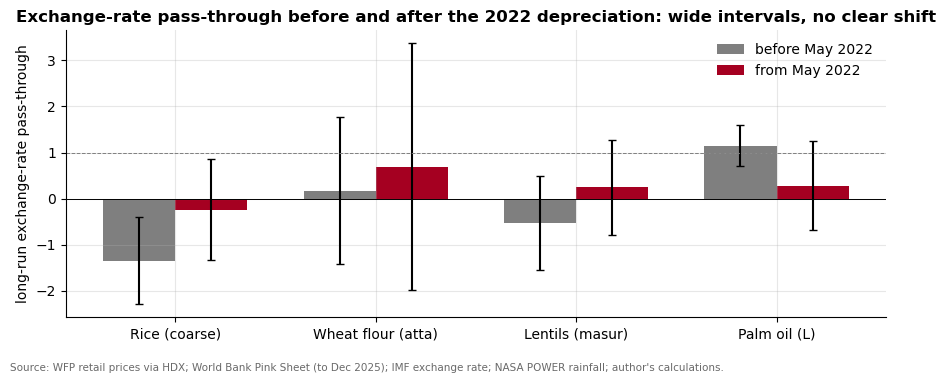

In [13]:
brk = []
for item in rg.STAPLES:
    y, X = rg.design(df, item, world="usd", interact=True)
    ols, hac = rg.fit(y, X)
    base = [c for c in X if c.startswith("fx_L") and "post" not in c]
    inter = [c for c in X if c.startswith("fx_L") and c.endswith("post2022")]
    b = rg.sum_test(hac, base); i = rg.sum_test(hac, inter); after = rg.sum_test(hac, base + inter)
    y0, X0 = rg.design(df, item, world="usd")
    f, p, k, dfd, npost = rg.chow(y0, X0, rg.DEPRECIATION)
    brk.append({"item": item, "fx_lr_before": b["sum"], "fx_lr_before_ci": f"{b['ci_low']:.2f} to {b['ci_high']:.2f}",
                "fx_lr_after": after["sum"], "fx_lr_after_ci": f"{after['ci_low']:.2f} to {after['ci_high']:.2f}",
                "change": i["sum"], "change_p": i["wald_p"], "chow_F": f, "chow_p": p, "chow_df": f"{k}, {dfd}",
                "n_post": npost})
    coefs.append(rg.coef_table(hac, "fx_interaction_2022", item))
brk_df = pd.DataFrame(brk); brk_df.round(4).to_csv(TAB / "regression_fx_break_2022.csv", index=False)
coef_df = pd.concat(coefs); coef_df.round(5).to_csv(TAB / "regression_main_coefficients.csv", index=False)
for _, r in brk_df.iterrows():
    fact(f"fx_change_post2022_{r['item']}", round(r.change, 3), "Sum of fx x post-May-2022 interaction coefficients (HAC)")
    fact(f"fx_change_post2022_{r['item']}_p", round(r.change_p, 3), "Wald p-value, H0: no change")
    fact(f"chow_2022_{r['item']}_p", round(r.chow_p, 3), "Chow F-test p-value, break at May 2022")
display(brk_df.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(brk_df))
for off, col, lab, c in [(-0.18, "fx_lr_before", "before May 2022", GREY), (0.18, "fx_lr_after", "from May 2022", RED)]:
    ci = brk_df[f"{col}_ci"].str.split(" to ", expand=True).astype(float)
    ax.bar(x + off, brk_df[col], width=0.36, color=c, label=lab)
    ax.errorbar(x + off, brk_df[col], yerr=[brk_df[col] - ci[0], ci[1] - brk_df[col]], fmt="none", color="k", capsize=3)
ax.axhline(0, color="k", lw=0.7); ax.axhline(1, color=GREY, lw=0.7, ls="--")
ax.set_xticks(x); ax.set_xticklabels([ITEM_LABEL[i] for i in brk_df["item"]])
ax.set_ylabel("long-run exchange-rate pass-through"); ax.legend()
ax.set_title("Exchange-rate pass-through before and after the 2022 depreciation: wide intervals, no clear shift")
save(fig, "fig27_fx_passthrough_2022", SRC_REG); plt.show()

## 6. Panel extension: division fixed effects

The national series averages six divisions. Using the six division series directly gives six times as many observations. Each division gets its own intercept (a fixed effect), which absorbs permanent differences such as transport costs to Sylhet or Barishal, and the slope on the world price is shared. Standard errors are clustered by month, because all divisions face the same world price in the same month.

In [14]:
dv = pd.read_parquet(PROC / "division_prices.parquet")
dv = dv[dv.item == "palm_oil"].pivot(index="date", columns="division", values="price_bdt")
dv = dv.reindex(df.index)
long = (100 * np.log(dv).diff()).stack().rename("dy").reset_index().rename(columns={"level_1": "division"})
long = long.rename(columns={long.columns[0]: "date"})
lagX = pd.DataFrame({f"world_L{k}": df.d_world_palm_oil_bdt.shift(k) for k in range(4)})
lagX = lagX.join(df[["rain_anom", "flood", "ramadan", "break2020", "month"]])
pan = long.merge(lagX, left_on="date", right_index=True).dropna()
fe = sm.OLS.from_formula("dy ~ world_L0 + world_L1 + world_L2 + world_L3 + rain_anom + flood + ramadan + break2020"
                         " + C(month) + C(division)", data=pan).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(pan.date)[0]})
pl = rg.sum_test(fe, [f"world_L{k}" for k in range(4)])
coefs.append(rg.coef_table(fe, "panel_division_fe", "palm_oil"))
coef_df = pd.concat(coefs); coef_df.round(5).to_csv(TAB / "regression_main_coefficients.csv", index=False)
fact("panel_palm_oil_lr", round(pl["sum"], 3), "Long-run pass-through, palm oil, division panel with fixed effects, SE clustered by month")
fact("panel_palm_oil_lr_ci", f"{pl['ci_low']:.2f} to {pl['ci_high']:.2f}", "95% CI of that sum")
fact("panel_palm_oil_n", int(fe.nobs), "Division-months in the panel")
f, p, k = rg.joint_f(fe, [c for c in fe.params.index if c.startswith("C(division)")])
fact("panel_division_fe_p", round(p, 4), "Wald test p-value that the division intercepts are equal")
print(f"National-series estimate: {po['sum']:.2f}; panel estimate: {pl['sum']:.2f}")

panel_palm_oil_lr: 0.661
panel_palm_oil_lr_ci: 0.45 to 0.88
panel_palm_oil_n: 1263
panel_division_fe_p: 0.9903
National-series estimate: 0.66; panel estimate: 0.66


## Summary

- Monthly changes in domestic staple prices are only weakly correlated with same-month world price changes. Palm oil, which Bangladesh imports almost entirely, has by far the strongest link.
- Regressions in price levels give high R² and badly autocorrelated residuals; that is the spurious-regression problem, and the analysis uses changes instead.
- The multiple regression with lags gives long-run (three-month) pass-through estimates that are largest for palm oil, smaller for atta, and small for rice. For all three we can reject full pass-through (a coefficient of 1). Lentils show no clear response to the exchange rate.
- Residuals have fat tails and some autocorrelation, so the inference relies on Newey-West errors. VIFs are low.
- A model fitted only to 2006-2019 predicts 2020-2025 palm oil price changes clearly better than a constant forecast (RMSE about 30% lower), so the palm oil relation held up after 2019. For atta the model does no better than the constant, and for rice and lentils it does worse.
- There is no clear evidence that exchange-rate pass-through changed after the 2022 depreciation, though the post-2022 sample is short and the intervals are wide.

The exact numbers are in the tables above and in `outputs/tables/key_facts_regression.csv`.

In [15]:
kf = pd.DataFrame(facts); kf.to_csv(TAB / "key_facts_regression.csv", index=False)
print(len(kf), "facts written"); kf

74 facts written


,fact,value,how_computed
0,sample_first_month,2006-01,First month loaded for notebook 04
1,sample_last_month,2025-12,Last month with Pink Sheet world prices
2,corr_rice_pearson,0.055,"Pearson r, monthly % change, Rice (coarse) vs ..."
3,corr_rice_ci,-0.07 to 0.18,Fisher-z 95% CI of that r
4,corr_rice_spearman,0.007,"Spearman rho, same pair"
...,...,...,...
69,chow_2022_palm_oil_p,0.998,"Chow F-test p-value, break at May 2022"
70,panel_palm_oil_lr,0.661,"Long-run pass-through, palm oil, division pane..."
71,panel_palm_oil_lr_ci,0.45 to 0.88,95% CI of that sum
72,panel_palm_oil_n,1263,Division-months in the panel
